In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

import binzli as bn

### Model data

In [2]:
x = np.linspace(-np.pi, np.pi, 500)
y = np.sin(x)

# Binning

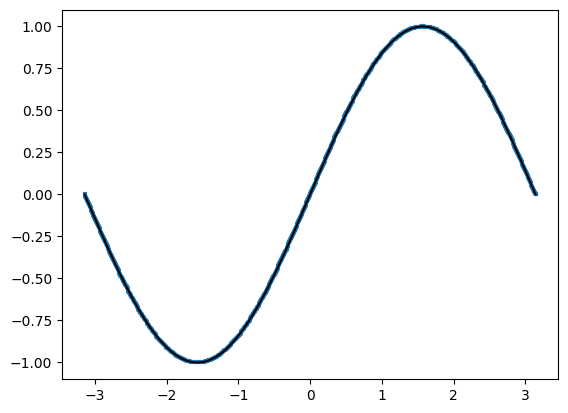

In [3]:
binned_sine = bn.BinnedData.new_from_xy(x=x, y=y)

# orignial
plt.plot(x, y, color="k", zorder=1)

# binned (in blue)
plt.step(
    binned_sine.centers,
    binned_sine.values,
    where="mid",
    lw=3,
    zorder=0
)

# Rebinning

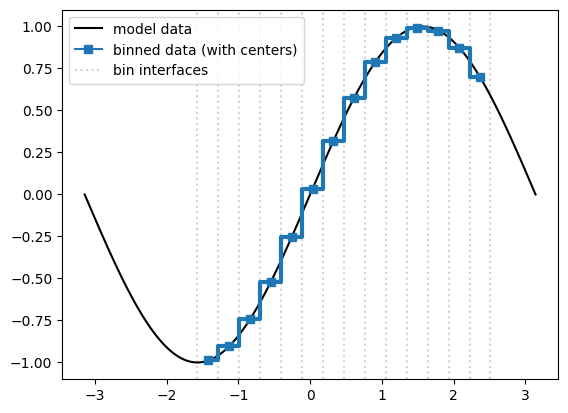

In [4]:
new_interfaces = np.linspace(-np.pi/2, np.pi/1.25, 15)
new_bins = bn.BinningScheme.new_from_interfaces(new_interfaces)

rebinned_sine = binned_sine.rebin_to_scheme(scheme=new_bins)

# orignial
plt.plot(x, y, color="k")

plt.step(
    rebinned_sine.centers,
    rebinned_sine.values,
    where="mid",
    lw=3,
    marker="s" # mark centers
)
for line_position in rebinned_sine.interfaces:
    plt.axvline(line_position, zorder=-1, ls="dotted", color="lightgrey")

handles = [
    mpl.lines.Line2D([], [], color="k", ls="solid", label="model data"),
    mpl.lines.Line2D([], [], color="tab:blue", marker="s", ls="solid", label="binned data (with centers)"),
    mpl.lines.Line2D([], [], color="lightgrey", ls="dotted", label="bin interfaces"),
]
plt.legend(loc=2, handles=handles)

# NOTE: the half step at the first and last bin are plotting artifacts 